# Starter: gspc-ai-economy-index

Mirror of Hugging Face csoai/gspc-ai-economy-index

Dataset: [nicktempleman/csoai-gspc-ai-economy-index](https://www.kaggle.com/datasets/nicktempleman/csoai-gspc-ai-economy-index) · Publisher: [Council of AI](https://councilof.ai) (CSOAI Ltd) · Hugging Face twin: [csoai/gspc-ai-economy-index](https://huggingface.co/datasets/csoai/gspc-ai-economy-index)

This notebook loads the files, shows shape and schema, and gives a few summary statistics and plots. It does not compute new measurements. Measurement is not certification; for the current board state use https://councilof.ai/api/gspc.

## 1. Locate the files

In [1]:
import os, json, glob
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATASET_REF = "nicktempleman/csoai-gspc-ai-economy-index"
SLUG = DATASET_REF.split("/")[1]
PREFERRED = 'manifest.jsonl'   # file chosen when this notebook was prepared; any tabular file works

def find_data_dir():
    env = os.environ.get("DATA_DIR")
    if env and Path(env).is_dir():
        return Path(env)
    for c in [Path("/kaggle/input") / SLUG,
              Path("/kaggle/input/datasets") / DATASET_REF]:
        if c.is_dir():
            return c
    root = Path("/kaggle/input")
    if root.is_dir():  # mount layouts differ between Kaggle images; search for the slug
        for p in root.rglob(SLUG):
            if p.is_dir():
                return p
    raise FileNotFoundError("Attach " + DATASET_REF + " as notebook input, or set DATA_DIR")

DATA_DIR = find_data_dir()
files = sorted(p for p in DATA_DIR.rglob("*") if p.is_file())
inventory = pd.DataFrame({
    "file": [str(p.relative_to(DATA_DIR)) for p in files],
    "ext": [p.suffix.lower() or "(none)" for p in files],
    "bytes": [p.stat().st_size for p in files],
})
print(DATA_DIR, "|", len(inventory), "files,", inventory.bytes.sum(), "bytes")
inventory.groupby("ext").agg(files=("file", "count"), bytes=("bytes", "sum")).sort_values("files", ascending=False)

/Users/nicholas/.claude-science/orgs/afd8d9ac-019f-4b20-9510-5402272d5585/workspaces/560da339-f920-41b7-8102-c57af3fc4b18/kg/localdata/csoai-gspc-ai-economy-index | 6 files, 8620 bytes


        files  bytes
ext                 
.json       3   2608
.jsonl      2   2839
.yaml       1   3173

## 2. Load a table
The loader reads Parquet, CSV, JSONL, a JSON list of records, or the largest record list inside a JSON object.

In [2]:
def load_table(path: Path, max_rows=200_000):
    """Return a DataFrame for csv/tsv/parquet/jsonl, or for a JSON list / JSON object holding a list of records."""
    ext = path.suffix.lower()
    if ext == ".parquet":
        return pd.read_parquet(path)
    if ext in (".csv", ".tsv"):
        return pd.read_csv(path, sep="\t" if ext == ".tsv" else ",", nrows=max_rows)
    if ext == ".jsonl":
        rows = []
        with open(path, encoding="utf-8") as fh:
            for i, line in enumerate(fh):
                if i >= max_rows:
                    break
                line = line.strip()
                if line:
                    try:
                        rows.append(json.loads(line))
                    except json.JSONDecodeError:
                        pass
        rows = [r for r in rows if isinstance(r, dict)]
        return pd.json_normalize(rows, max_level=0) if rows else None
    if ext == ".json":
        doc = json.loads(path.read_text(encoding="utf-8"))
        if isinstance(doc, list) and doc and all(isinstance(r, dict) for r in doc[:50]):
            return pd.json_normalize(doc, max_level=0)
        if isinstance(doc, dict):
            lists = {k: v for k, v in doc.items() if isinstance(v, list) and v and all(isinstance(r, dict) for r in v[:50])}
            if lists:
                key = max(lists, key=lambda k: len(lists[k]))
                print("records taken from key:", key)
                return pd.json_normalize(lists[key], max_level=0)
    return None

candidates = [DATA_DIR / PREFERRED] if PREFERRED and (DATA_DIR / PREFERRED).exists() else []
candidates += [p for p in files if p.suffix.lower() in (".parquet", ".csv", ".tsv", ".jsonl", ".json")]
df, source = None, None
for p in candidates:
    try:
        t = load_table(p)
    except Exception as exc:  # keep going: some JSON files are documents, not tables
        print("skip", p.name, type(exc).__name__)
        continue
    if t is not None and len(t.columns) > 1 and len(t) > 0:
        df, source = t, p
        break
assert df is not None, "no tabular file found"
print("table:", source.relative_to(DATA_DIR), "| shape:", df.shape)
df.head()

table: manifest.jsonl | shape: (6, 8)


                 file   bytes                                       sha   ext                                                                                          url                         repo                 as_of                                                                     source
0           README.md  2635.0  58b2005fc1442e7a9cc75c732f4ed1af1bbccbc3    md           https://huggingface.co/datasets/csoai/gspc-ai-economy-index/resolve/main/README.md  csoai/gspc-ai-economy-index  2026-09-04T04:33:29Z  https://huggingface.co/api/datasets/csoai/gspc-ai-economy-index/tree/main
1  coverage-card.json  1095.0  2f77c078a8dbdc2ab56eee2d25ad249059317df8  json  https://huggingface.co/datasets/csoai/gspc-ai-economy-index/resolve/main/coverage-card.json  csoai/gspc-ai-economy-index  2026-09-04T04:33:29Z  https://huggingface.co/api/datasets/csoai/gspc-ai-economy-index/tree/main
2           eval.yaml  1022.0  ccad3003d7557655c55d306580776562a85aa84c  yaml           https://huggingface.c

## 3. Schema

In [3]:
def kind(s):
    v = s.dropna()
    if v.empty: return "empty"
    return type(v.iloc[0]).__name__

schema = pd.DataFrame({"dtype": df.dtypes.astype(str),
                       "python_type": [kind(df[c]) for c in df.columns],
                       "non_null": df.notna().sum(),
                       "null_share": df.isna().mean().round(3)})
schema

          dtype python_type  non_null  null_share
file     object         str         6       0.000
bytes   float64     float64         5       0.167
sha      object         str         5       0.167
ext      object         str         6       0.000
url      object         str         6       0.000
repo     object         str         6       0.000
as_of    object         str         6       0.000
source   object         str         6       0.000

## 4. Summary statistics

In [4]:
scalar = df[[c for c in df.columns if df[c].map(lambda v: not isinstance(v, (list, dict))).all()]]
num = scalar.select_dtypes("number")
print("numeric columns:", list(num.columns))
display(num.describe().T) if not num.empty else print("no numeric columns")
cat_cols = [c for c in scalar.columns if c not in num.columns and 1 < scalar[c].nunique() <= 30]
for c in cat_cols[:3]:
    print("\n", c); print(scalar[c].value_counts().head(10).to_string())

numeric columns: ['bytes']

 file
file
README.md             1
coverage-card.json    1
eval.yaml             1
input-schema.json     1
skeleton.json         1
manifest.jsonl        1

 sha
sha
58b2005fc1442e7a9cc75c732f4ed1af1bbccbc3    1
2f77c078a8dbdc2ab56eee2d25ad249059317df8    1
ccad3003d7557655c55d306580776562a85aa84c    1
b32705180a50d899b26fa2a621807a2fea9b401b    1
d714345a4706fcc529c17d842a96c8702448ecd3    1

 ext
ext
json     3
md       1
yaml     1
jsonl    1


       count    mean         std    min     25%     50%     75%     max
bytes    5.0  1396.0  716.356057  861.0  1022.0  1095.0  1367.0  2635.0

## 5. Plots

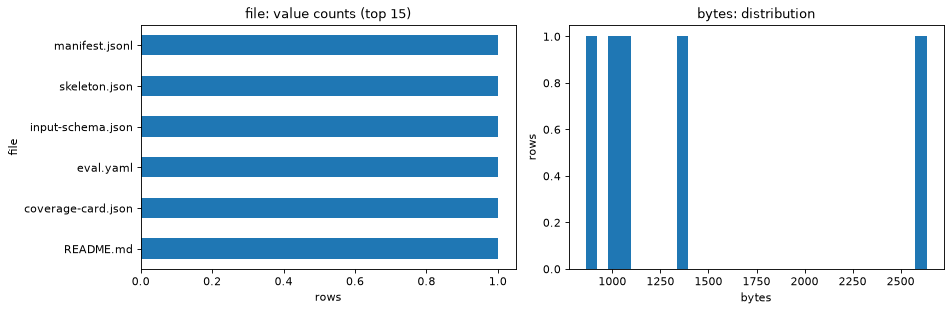

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if cat_cols:
    c = cat_cols[0]
    scalar[c].astype(str).value_counts().head(15).sort_values().plot.barh(ax=axes[0])
    axes[0].set_title(f"{c}: value counts (top 15)"); axes[0].set_xlabel("rows")
else:
    axes[0].axis("off"); axes[0].text(0.5, 0.5, "no low-cardinality column", ha="center")
if not num.empty:
    c = num.columns[num.notna().sum().argmax()]
    num[c].dropna().plot.hist(ax=axes[1], bins=30)
    axes[1].set_title(f"{c}: distribution"); axes[1].set_xlabel(c); axes[1].set_ylabel("rows")
else:
    df.notna().mean().sort_values().tail(15).plot.barh(ax=axes[1])
    axes[1].set_title("share of non-null values per column"); axes[1].set_xlabel("share of rows")
fig.tight_layout(); plt.show()

## Notes
- Keep the Kaggle version number with any result; the files are a dated snapshot.
- Null means absent or not applicable, not zero.
- Dataset licence: CC-BY-4.0.